# A12 confidence per LGA

How much the data behind an LGA's cards can be trusted. Each input scores 0 (weak) to 2 (strong): cropland share, how much vegetation data was cloud-filled, the soil map's own uncertainty, and the vegetation stress evidence (0 everywhere while A6 has no skill). The rotation engine adds each template's evidence strength. Formulas: `model/confidence.py`. Cut-offs: `config/models.yaml` (`confidence`).

## Imports

In [1]:
# Third-party libraries only. Project code is imported two cells down, after the path
# setup, so this cell runs in any fresh kernel.
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Path setup: makes the notebook work whether Jupyter starts in notebooks/ or the repo
# root, and lets `import model` find the project package.
# Run from notebooks/ or the repo root: config paths are relative to the repo root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Project code: the tested functions in model/. The notebook calls them; it never
# redefines them, so its results match `python -m model.build` exactly.
from model import confidence as cf
from model.io import write_csv
from model.settings import load_model_config
from model.water_pipeline import canonical_lga

## 1. Inputs

In [4]:
# Load the inputs for every LGA: cropland share, the share of NDVI composites that were
# cloud-filled, and iSDA's relative uncertainty width for sand, clay and organic carbon.
# Scope: all 23 Kaduna LGAs.
cfg = load_model_config()
k = cfg.confidence
static = pd.read_parquet(cfg.paths.static_features).set_index("lga")
lgas = list(static.index)
isda = pd.read_csv(cfg.paths.isda_stats)
isda = isda.assign(lga=canonical_lga(isda["lga"], lgas)).set_index("lga")
comp = pd.read_csv(cfg.paths.ndvi_composites)
comp["lga"] = canonical_lga(comp["lga"], lgas)
b = cfg.bare_fields
filled = (
    comp[comp["year"].between(b.years.start, b.years.end)].groupby("lga")["interpolated"].mean()
)
width = cf.soil_relative_width(isda, ["sand_content", "clay_content", "carbon_organic"], "0_20")
pd.DataFrame(
    {
        "cropland_share": static["cropland_share"],
        "ndvi_filled_share": filled,
        "soil_relative_width": width,
    }
).describe().round(3)

,cropland_share,ndvi_filled_share,soil_relative_width
count,23.000,23.000,23.000
mean,0.501,0.090,0.221
std,0.267,0.040,0.023
min,0.065,0.026,0.182
25%,0.289,0.061,0.203
50%,0.508,0.082,0.221
75%,0.743,0.122,0.239
max,0.927,0.156,0.258


## 2. Score, total and level

In [5]:
# Score each input 0 to 2 against the cut-offs in config, add them up (out of 8), map the
# total to High, Medium or Low, and name the weakest input as the reason.
scores = pd.DataFrame(
    {
        "cropland": cf.score_higher_better(static["cropland_share"], k.cropland_share),
        "vegetation_data": cf.score_lower_better(
            filled.reindex(static.index), k.ndvi_interpolated_share
        ),
        "soil": cf.score_lower_better(width.reindex(static.index), k.soil_relative_width),
        "vegetation_stress": k.vegetation_stress,
    }
)
scores["total"] = scores.sum(axis=1)
scores["level"] = cf.level(scores["total"], k.levels)
scores["reason"] = cf.weakest_reason(scores)
scores["level"].value_counts()

level
Medium    14
Low        5
High       4
Name: count, dtype: int64

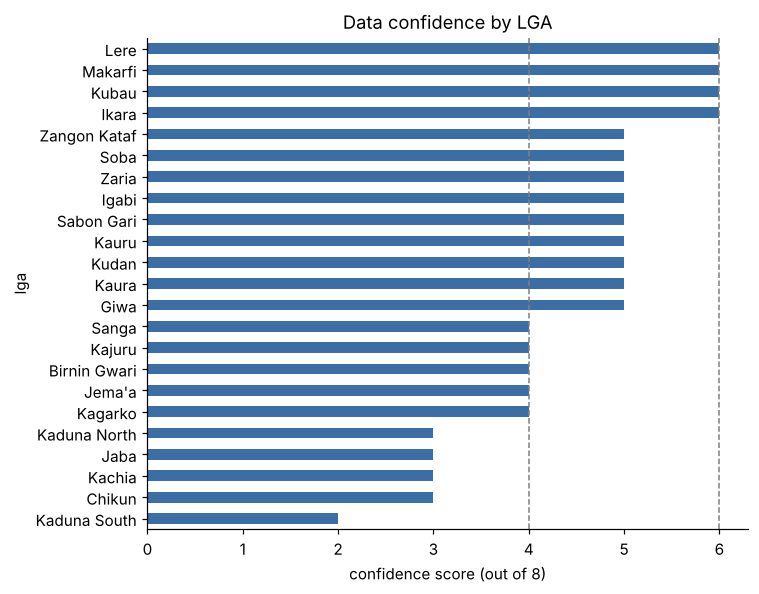

In [6]:
# All 23 LGAs ranked by total score, with the Medium and High cut-offs.
ax = scores["total"].sort_values().plot.barh(figsize=(7, 5.5), color="#3b6ea5")
ax.set_xlabel("confidence score (out of 8)")
ax.axvline(k.levels["Medium"], ls="--", color="grey", lw=1)
ax.axvline(k.levels["High"], ls="--", color="grey", lw=1)
ax.set_title("Data confidence by LGA")
plt.tight_layout()

The soil input scores 2 everywhere: iSDA's own uncertainty is about the same in every LGA, so it cannot separate them (the card still says soil is a satellite estimate). Confidence differences come from cropland share and cloud-filled vegetation data, which are worst in the wetter, more wooded south.

## 3. Save

In [7]:
# Save the A12 table: scores, level, reason and the raw inputs for every LGA.
write_csv(
    scores.join(
        pd.DataFrame(
            {
                "cropland_share": static["cropland_share"],
                "ndvi_filled_share": filled,
                "soil_relative_width": width,
            }
        )
    ).reset_index(names="lga"),
    cfg.paths.output_dir / "a12" / "a12_lga_confidence.csv",
)

PosixPath('data/processed/models/a12/a12_lga_confidence.csv')